In [3]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

PRIMARY_URL = "https://raw.githubusercontent.com/sriharikadali/Students-Performance-in-Exams/master/StudentsPerformance.csv"
FALLBACK_URL = "https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv"


def load_students_performance(primary_url: str, fallback_url: str):
    """
    Загружает CSV непосредственно по HTTPS.
    Сначала используется URL из задания, затем резервный URL.
    """
    errors = []

    for url in (primary_url, fallback_url):
        try:
            with urllib.request.urlopen(url, timeout=30) as response:
                raw_bytes = response.read()

            dataframe = pd.read_csv(io.BytesIO(raw_bytes))

            required_columns = {
                "gender",
                "race/ethnicity",
                "parental level of education",
                "lunch",
                "test preparation course",
                "math score",
                "reading score",
                "writing score",
            }

            missing_columns = required_columns - set(dataframe.columns)
            if missing_columns:
                raise ValueError(
                    f"Отсутствуют обязательные столбцы: {sorted(missing_columns)}"
                )

            return dataframe, url

        except Exception as exc:
            errors.append(
                f"{url} -> {type(exc).__name__}: {exc}"
            )

    raise RuntimeError(
        "Не удалось загрузить датасет.\n" + "\n".join(errors)
    )


df_raw, USED_URL = load_students_performance(PRIMARY_URL, FALLBACK_URL)

print("Dataset loaded successfully / Датасет успешно загружен")
print("Used URL / Использованный URL:")
print(USED_URL)
print("Shape / Размер:", df_raw.shape)

display(df_raw.head())


Dataset loaded successfully / Датасет успешно загружен
Used URL / Использованный URL:
https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv
Shape / Размер: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
score_cols = ["math score", "reading score", "writing score"]

categorical_cols = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
]

print("Rows, columns / Строки, столбцы:", df_raw.shape)

print("\n--- INFO ---")
df_raw.info()

print("\n--- FIRST ROWS / ПЕРВЫЕ СТРОКИ ---")
display(df_raw.head())

missing_report = df_raw.isna().sum().to_frame("missing_count")
missing_report["missing_percent"] = (
    missing_report["missing_count"] / len(df_raw) * 100
)

print("\n--- MISSING VALUES / ПРОПУСКИ ---")
display(missing_report)

duplicate_count = int(df_raw.duplicated().sum())
print("Exact duplicates / Полные дубликаты:", duplicate_count)

print("\n--- NUMERIC DESCRIPTION / ЧИСЛОВАЯ СТАТИСТИКА ---")
display(df_raw[score_cols].describe().T)

range_check = pd.DataFrame({
    "below_0": (df_raw[score_cols] < 0).sum(),
    "above_100": (df_raw[score_cols] > 100).sum(),
})

print("\n--- RANGE CHECK 0..100 / ПРОВЕРКА ДИАПАЗОНА ---")
display(range_check)

for col in categorical_cols:
    print(f"\nColumn / Столбец: {col}")
    display(df_raw[col].value_counts(dropna=False).to_frame("count"))


Rows, columns / Строки, столбцы: (1000, 8)

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

--- FIRST ROWS / ПЕРВЫЕ СТРОКИ ---


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



--- MISSING VALUES / ПРОПУСКИ ---


,missing_count,missing_percent
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


Exact duplicates / Полные дубликаты: 0

--- NUMERIC DESCRIPTION / ЧИСЛОВАЯ СТАТИСТИКА ---


...

,count
parental level of education,
some college,226
associate's degree,222
high school,196
some high school,179
bachelor's degree,118
master's degree,59



Column / Столбец: lunch


,count
lunch,
standard,645
free/reduced,355



Column / Столбец: test preparation course


,count
test preparation course,
none,642
completed,358


In [5]:
df = df_raw.copy()

# Удаление полных дублей, если они есть.
n_before = len(df)
df = df.drop_duplicates().copy()
n_after = len(df)

print(
    "Removed exact duplicates / Удалено полных дублей:",
    n_before - n_after
)

# Медианная импутация числовых полей.
for col in score_cols:
    missing_before = int(df[col].isna().sum())
    median_value = df[col].median()

    df[col] = df[col].fillna(median_value)

    print(
        f"{col}: NaN before={missing_before}; "
        f"median={median_value:.2f}"
    )

# Импутация модой категориальных полей.
for col in categorical_cols:
    missing_before = int(df[col].isna().sum())

    if missing_before > 0:
        mode_series = df[col].mode(dropna=True)

        if mode_series.empty:
            raise ValueError(
                f"Невозможно определить моду для столбца {col}"
            )

        mode_value = mode_series.iloc[0]
        df[col] = df[col].fillna(mode_value)
    else:
        mode_value = "not required / не требуется"

    print(
        f"{col}: NaN before={missing_before}; "
        f"mode={mode_value}"
    )

print("\nNaN after imputation / Пропуски после импутации:")
display(df.isna().sum().to_frame("missing_count"))


Removed exact duplicates / Удалено полных дублей: 0
math score: NaN before=0; median=66.00
reading score: NaN before=0; median=70.00
writing score: NaN before=0; median=69.00
gender: NaN before=0; mode=not required / не требуется
race/ethnicity: NaN before=0; mode=not required / не требуется
parental level of education: NaN before=0; mode=not required / не требуется
lunch: NaN before=0; mode=not required / не требуется
test preparation course: NaN before=0; mode=not required / не требуется

NaN after imputation / Пропуски после импутации:


,missing_count
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [6]:
iqr_bounds = {}
outlier_mask = pd.Series(False, index=df.index)

for col in score_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_bounds[col] = {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower": lower,
        "upper": upper,
    }

    current_outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    )

    outlier_mask = outlier_mask | current_outliers

bounds_df = pd.DataFrame(iqr_bounds).T

bounds_df["outlier_count"] = [
    int(
        (
            (df[col] < bounds_df.loc[col, "lower"]) |
            (df[col] > bounds_df.loc[col, "upper"])
        ).sum()
    )
    for col in score_cols
]

display(bounds_df.round(3))

print(
    "Rows with >=1 IQR outlier / "
    "Строк с хотя бы одним IQR-выбросом:",
    int(outlier_mask.sum())
)

df_clean = df.loc[~outlier_mask].copy()

print("Rows before / Строк до очистки:", len(df))
print("Rows after / Строк после очистки:", len(df_clean))
print("Removed / Удалено:", len(df) - len(df_clean))

# Контроль качества после очистки.
assert df_clean[score_cols].notna().all().all()
assert (
    ((df_clean[score_cols] >= 0) &
     (df_clean[score_cols] <= 100))
    .all()
    .all()
)

display(df_clean.head())


,Q1,Q3,IQR,lower,upper,outlier_count
math score,57.00,77.0,20.00,27.000,107.000,8
reading score,59.00,79.0,20.00,29.000,109.000,6
writing score,57.75,79.0,21.25,25.875,110.875,5


Rows with >=1 IQR outlier / Строк с хотя бы одним IQR-выбросом: 12
Rows before / Строк до очистки: 1000
Rows after / Строк после очистки: 988
Removed / Удалено: 12


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [7]:
df_normalized = df_clean.copy()

for col in score_cols:
    x_min = df_clean[col].min()
    x_max = df_clean[col].max()

    if x_max == x_min:
        df_normalized[col + "_norm"] = 0.0
    else:
        df_normalized[col + "_norm"] = (
            (df_clean[col] - x_min) /
            (x_max - x_min)
        )

norm_cols = [col + "_norm" for col in score_cols]
display(df_normalized[norm_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
math score_norm,988.0,0.542815,0.197389,0.0,0.410959,0.534247,0.684932,1.0
reading score_norm,988.0,0.572404,0.197419,0.0,0.436620,0.577465,0.718310,1.0
writing score_norm,988.0,0.569408,0.198976,0.0,0.424658,0.575342,0.712329,1.0


In [8]:
df_v9 = df_clean.loc[
    df_clean["lunch"].eq("free/reduced")
].copy()

group_counts = (
    df_v9["test preparation course"]
    .value_counts()
    .rename_axis("test_preparation")
    .to_frame("n")
)

print(
    "Variant 9 sample / Выборка варианта №9:",
    df_v9.shape
)

display(group_counts)

group_stats = (
    df_v9
    .groupby("test preparation course")[score_cols]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

display(group_stats.round(2))


Variant 9 sample / Выборка варианта №9: (345, 8)


,n
test_preparation,
none,215
completed,130


math score                               reading score                                \
                             count   mean median    std min  max         count   mean median    std min  max   
test preparation course                                                                                        
completed                      130  63.35   64.0  14.04  29  100           130  70.07   71.0  14.02  37  100   
none                           215  57.99   59.0  13.35  27   93           215  62.99   62.0  12.99  29   92   

                        writing score                                
                                count   mean median    std min  max  
test preparation course                                              
completed                         130  70.62   72.0  13.57  38  100  
none                              215  60.17   60.0  13.08  27   93

Среди учащихся прошедшие подготовительный курс в среднем набрали на 7.08 балла больше по чтению, чем те, кто подготовку не проходил.

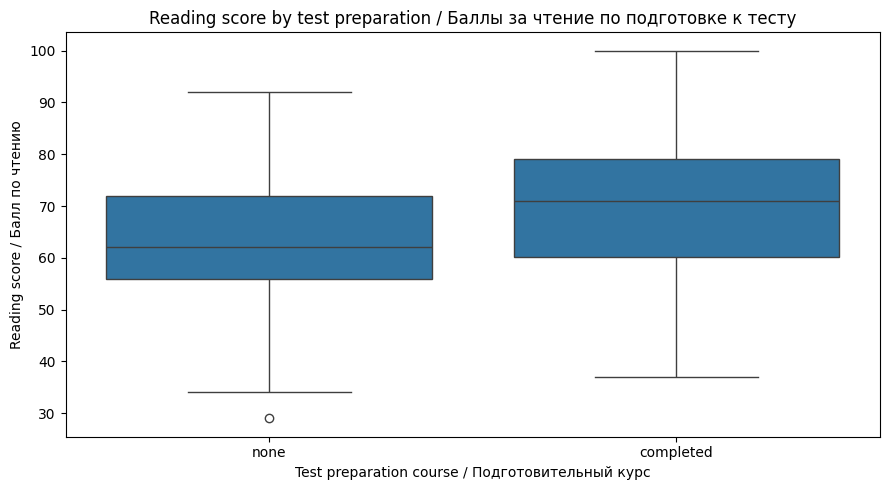

In [9]:
# 1. BOXPLOT
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_v9,
    x="test preparation course",
    y="reading score"
)

plt.title(
    "Reading score by test preparation / "
    "Баллы за чтение по подготовке к тесту"
)
plt.xlabel(
    "Test preparation course / Подготовительный курс"
)
plt.ylabel(
    "Reading score / Балл по чтению"
)

plt.tight_layout()
plt.show()


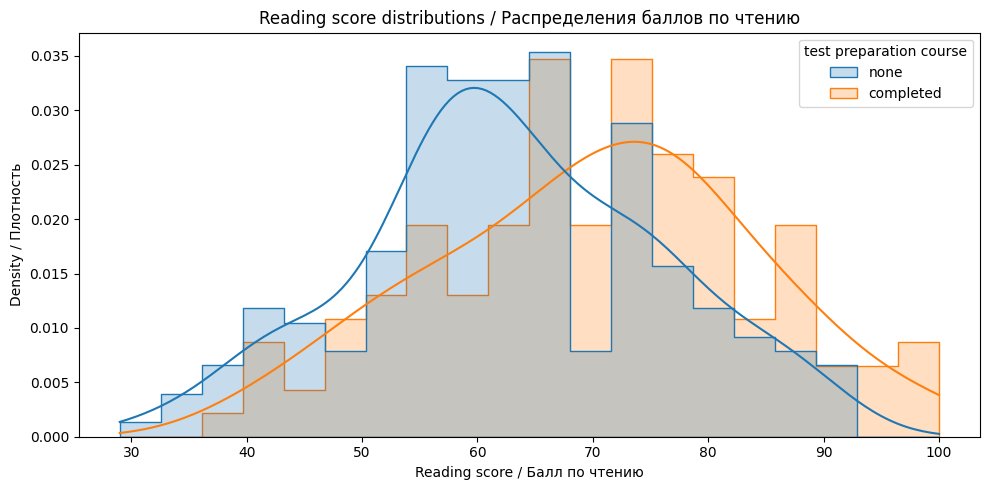

In [11]:
# 2. HISTPLOT
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_v9,
    x="reading score",
    hue="test preparation course",
    bins=20,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title(
    "Reading score distributions / "
    "Распределения баллов по чтению"
)
plt.xlabel("Reading score / Балл по чтению")
plt.ylabel("Density / Плотность")

plt.tight_layout()
plt.show()


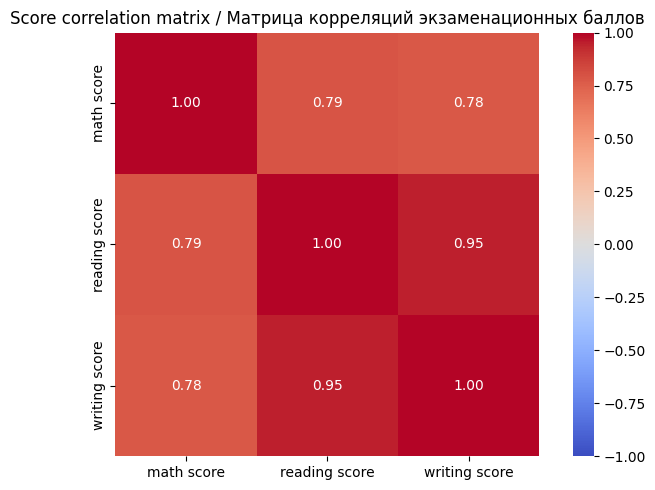

,math score,reading score,writing score
math score,1.000,0.795,0.777
reading score,0.795,1.000,0.949
writing score,0.777,0.949,1.000


In [13]:
# 3. CORRELATION HEATMAP
corr_matrix = df_v9[score_cols].corr(method="pearson")

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.title(
    "Score correlation matrix / "
    "Матрица корреляций экзаменационных баллов"
)

plt.tight_layout()
plt.show()

display(corr_matrix.round(3))


Предварительно можно сделать вывод, что учащиеся, прошедшие подготовительный курс, в среднем показывают более высокие результаты по чтению.

In [18]:
completed = df_v9.loc[
    df_v9["test preparation course"].eq("completed"),
    "reading score"
].astype(float)

none_group = df_v9.loc[
    df_v9["test preparation course"].eq("none"),
    "reading score"
].astype(float)

print("completed: n =", len(completed))
print("none:      n =", len(none_group))
print(f"completed mean = {completed.mean():.3f}")
print(f"none mean      = {none_group.mean():.3f}")
print(
    f"mean difference = "
    f"{completed.mean() - none_group.mean():.3f}"
)

# Современные scipy поддерживают alternative="greater".
# Блок except оставлен для совместимости со старыми средами.
try:
    result = stats.ttest_ind(
        completed,
        none_group,
        equal_var=False,
        alternative="greater"
    )

    t_stat = float(result.statistic)
    p_value = float(result.pvalue)

except TypeError:
    result = stats.ttest_ind(
        completed,
        none_group,
        equal_var=False
    )

    t_stat = float(result.statistic)
    p_two_sided = float(result.pvalue)

    if t_stat > 0:
        p_value = p_two_sided / 2
    else:
        p_value = 1 - p_two_sided / 2

alpha = 0.05

print("\nWelch one-sided t-test")
print(f"t = {t_stat:.4f}")
print(f"p = {p_value:.8g}")
print(f"alpha = {alpha}")


completed: n = 130
none:      n = 215
completed mean = 70.069
none mean      = 62.991
mean difference = 7.079

Welch one-sided t-test
t = 4.6702
p = 2.4304525e-06
alpha = 0.05


Следовательно, в данной выборке учащиеся, прошедшие подготовительный курс, имеют статистически значимо более высокий средний балл по чтению, чем учащиеся, не проходившие подготовку.

In [19]:
def cohens_d_independent(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    nx = len(x)
    ny = len(y)

    sx2 = np.var(x, ddof=1)
    sy2 = np.var(y, ddof=1)

    pooled_sd = np.sqrt(
        ((nx - 1) * sx2 + (ny - 1) * sy2) /
        (nx + ny - 2)
    )

    if pooled_sd == 0:
        return 0.0

    return (
        np.mean(x) - np.mean(y)
    ) / pooled_sd


d = cohens_d_independent(completed, none_group)

if abs(d) < 0.2:
    magnitude = "very small / очень малый"
elif abs(d) < 0.5:
    magnitude = "small / малый"
elif abs(d) < 0.8:
    magnitude = "medium / средний"
else:
    magnitude = "large / большой"

print(f"Cohen's d = {d:.3f}")
print(
    "Effect magnitude / Размер эффекта:",
    magnitude
)


Cohen's d = 0.529
Effect magnitude / Размер эффекта: medium / средний


Между учащимися, прошедшими подготовительный курс , и учащимися, не проходившими его , является не только статистически значимым, но и заметным по величине. Средний балл по чтению у учащихся группы completed оказался выше примерно на 7,08 балла, а значение Cohen's d показывает, что эта разница имеет практическое значение и не является незначительным эффектом.

In [20]:
mean_completed = completed.mean()
mean_none = none_group.mean()
difference = mean_completed - mean_none

print("=" * 78)
print("STATISTICAL CONCLUSION / СТАТИСТИЧЕСКИЙ ВЫВОД")
print("=" * 78)

if p_value < alpha and difference > 0:
    print(
        f"p={p_value:.8g} < {alpha}. "
        "H0 отклоняется в пользу H1."
    )
    print(
        f"Средний reading score: completed="
        f"{mean_completed:.2f}; none={mean_none:.2f}."
    )
    print(
        f"Разница средних = {difference:.2f} балла."
    )
else:
    print(
        f"p={p_value:.8g}. "
        "Недостаточно оснований подтвердить "
        "направленную альтернативную гипотезу."
    )

print("\n" + "=" * 78)
print("PEDAGOGICAL INTERPRETATION / ПЕДАГОГИЧЕСКИЙ ВЫВОД")
print("=" * 78)

print(
    "В анализируемой выборке можно говорить о статистической связи "
    "между прохождением подготовительного курса и результатом по чтению."
)

print(
    "Нельзя утверждать, что курс является доказанной причиной различия: "
    "на результаты могли влиять исходный уровень подготовки, мотивация "
    "и другие неучтённые факторы."
)

print(
    "Для школьного урока корректная формулировка: "
    "'В этой выборке группы различаются' — "
    "а не 'курс гарантированно повышает балл'."
)


STATISTICAL CONCLUSION / СТАТИСТИЧЕСКИЙ ВЫВОД
p=2.4304525e-06 < 0.05. H0 отклоняется в пользу H1.
Средний reading score: completed=70.07; none=62.99.
Разница средних = 7.08 балла.

PEDAGOGICAL INTERPRETATION / ПЕДАГОГИЧЕСКИЙ ВЫВОД
В анализируемой выборке можно говорить о статистической связи между прохождением подготовительного курса и результатом по чтению.
Нельзя утверждать, что курс является доказанной причиной различия: на результаты могли влиять исходный уровень подготовки, мотивация и другие неучтённые факторы.
Для школьного урока корректная формулировка: 'В этой выборке группы различаются' — а не 'курс гарантированно повышает балл'.
